In [1]:
!pip install cleverminer
!pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Cleverminer version  1.2.4


C:\Users\petrm\AppData\Local\Temp\ipykernel_69204\4084968967.py:8: DtypeWarning: Columns (0: Casualties, 1: District2+) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('https://www.cleverminer.org/data/accidents.zip', encoding='cp1250', sep='\t')


Cleverminer version 1.2.4.
Starting data preparation ...
Automatically reordering numeric categories ...
Automatically reordering numeric categories ...done
Encoding columns into bit-form...
Encoding columns into bit-form...done
Data preparation finished.
Will go for  4ftMiner
Starting to mine rules.
100%|####################################################|Elapsed Time: 0:00:0000
Done. Total verifications : 72, rules 3, times: prep 0.59sec, processing 0.08sec

CleverMiner task processing summary:

Task type : 4ftMiner
Number of verifications : 72
Number of rules : 3
Total time needed : 00h 00m 00s
Time of data preparation : 00h 00m 00s
Time of rule mining : 00h 00m 00s


List of rules:
RULEID BASE  CONF  AAD    Rule
     1  2517 0.328 +0.522 Driver_Age_Band(46 - 55) & Sex(Male) & Speed_limit(60) => Severity(Fatal Serious) | ---
     2  2598 0.036 +0.896 Sex(Male) & Speed_limit(60) => Severity(Fatal) | ---
     3  3064 0.030 +0.583 Speed_limit(60) => Severity(Fatal) | ---



Rule id : 

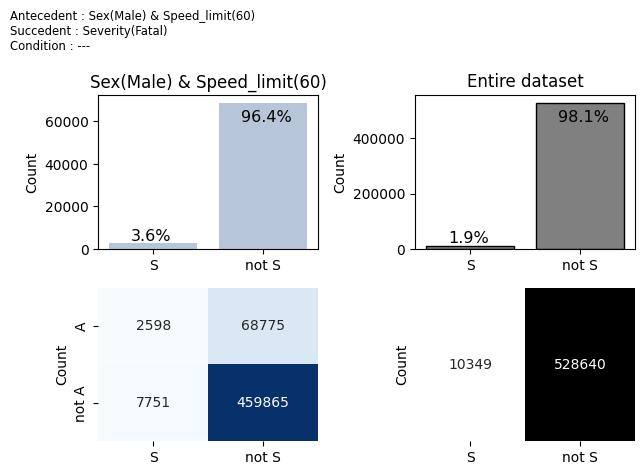

In [2]:
import pandas as pd
import sys

from sklearn.impute import SimpleImputer
from cleverminer import *

# read the data
df = pd.read_csv('https://www.cleverminer.org/data/accidents.zip', encoding='cp1250', sep='\t')
df = df[['Driver_Age_Band', 'Sex', 'Speed_limit', 'Severity']]

# handle missing values
imputer = SimpleImputer(strategy="most_frequent")
df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

clm = cleverminer(df=df, proc='4ftMiner',
                                  quantifiers={'Base': 2000, 'aad': 0.5},
                                  ante = clm_vars(['Driver_Age_Band', 'Sex', 'Speed_limit']),
                                  succ = { 'attributes': [clm_lcut('Severity')],'minlen': 1, 'maxlen': 1, 'type': 'con'})

clm.print_summary()
clm.print_rulelist()
clm.print_rule(2)
clm.draw_rule(2)